# Function 4 - Week 5: Observation Review

#### Review of Measured Outputs and Input Profiles up to and including Week 4 return, received on **23 October 2026**.

In [1]:
# Imports and shared helpers.
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from exploration_review_helpers import load_exploration_review
from observation_review_helpers import (
    prepare_weekly_observation_review, read_saved_forecast,
    plot_input_profiles, plot_output_review, plot_round_progress,
)
from query_budget import remaining_queries

In [2]:
# Settings for this run.
FUNCTION_NUMBER = 4
CURRENT_WEEK = 5
INPUT_COLUMNS = ["x1", "x2", "x3", "x4"]
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 30, 1: 1, 2: 1, 3: 1, 4: 1}
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
HISTORICAL_MODEL_PATH = ANALYSIS_DIR.parents[1] / "Week_04" / "model_predictions.ipynb"
STRONGEST_COUNT = 5
PORTAL_DECIMALS = 6

In [3]:
# Validate the snapshot, then prepare rankings and official round history.
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
prepared = prepare_weekly_observation_review(review, strongest_count=STRONGEST_COUNT)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))

,observation_id,source_round,x1,x2,x3,x4,y,output_rank
33,round-04,4,0.354513,0.376712,0.37896,0.488593,-1.25916,3


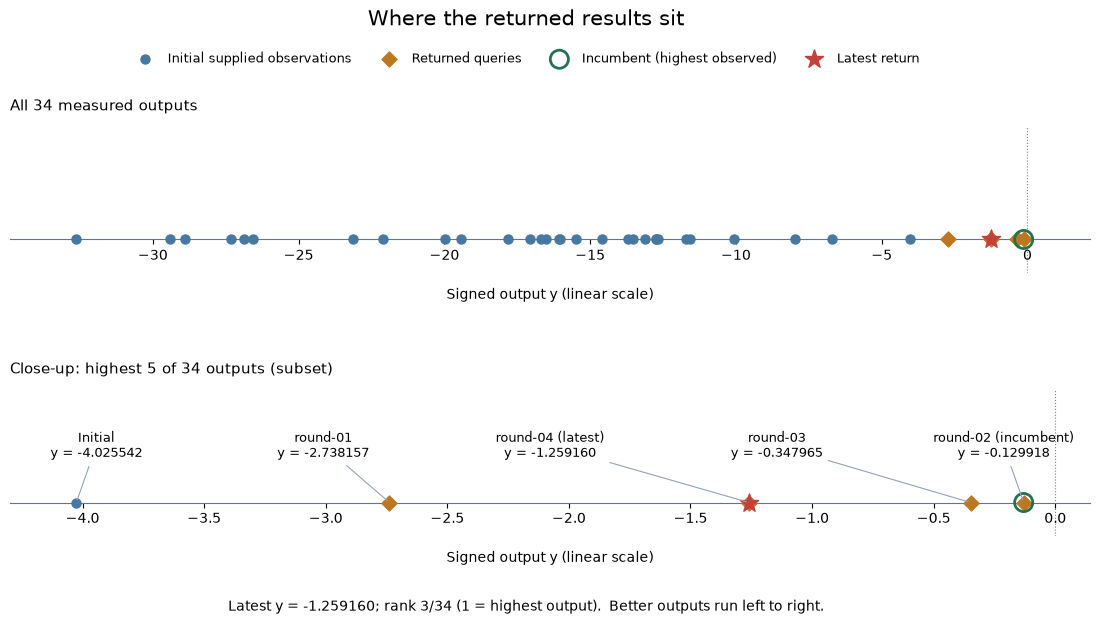

In [4]:
# Full signed range and a labelled highest-five subset; every row remains in the data.
plot_output_review(review, save_to=FIGURES_DIR / "observed-output-review.png")

,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,—,-4.025542,—
Round 1,-2.738157,-2.738157,1.287385
Round 2,-0.129918,-0.129918,2.608239
Round 3,-0.347965,-0.129918,-0.218047
Round 4,-1.259160,-0.129918,-1.129242


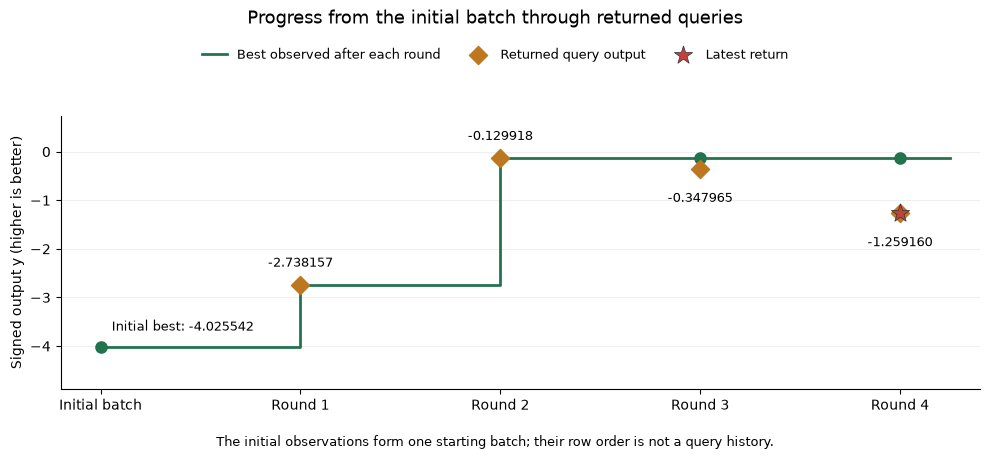

In [5]:
# Per-source peer round labels do not enter the owner's history.
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]]
    .rename(columns={"returned_y": "Returned output", "best_y": "Best observed after stage",
                     "change_vs_prior_best": "Return minus previous best"})
    .style.format(precision=PORTAL_DECIMALS, na_rep="—"))
plot_round_progress(prepared["progress"], save_to=FIGURES_DIR / "observed-progress.png")

,rank,source_round,x1,x2,x3,x4,y
observation_id,,,,,,,
round-02,1,2,0.445520,0.390792,0.374106,0.377372,-0.129918
round-03,2,3,0.459127,0.368781,0.430162,0.390645,-0.347965
round-04,3,4,0.354513,0.376712,0.378960,0.488593,-1.259160
round-01,4,1,0.377878,0.477308,0.239218,0.435290,-2.738157
initial-028,5,0,0.577766,0.428772,0.425826,0.249007,-4.025542


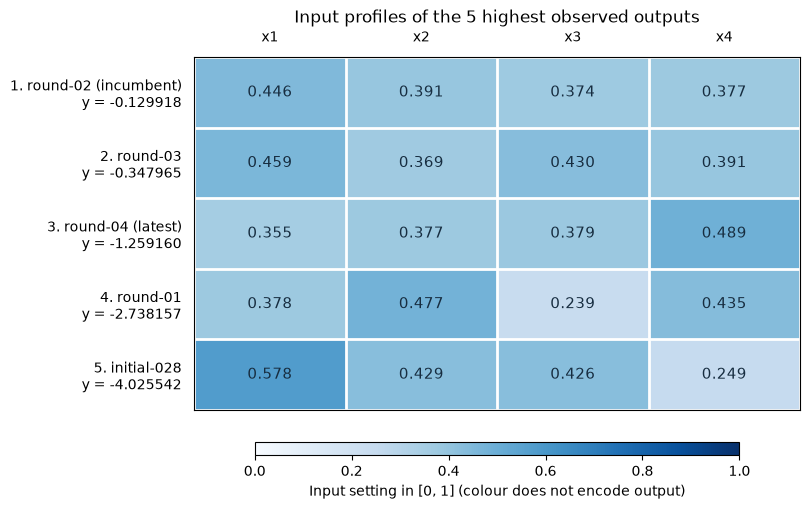

In [6]:
# Keep every input in the measured profiles; colour encodes input settings, not output.
display(prepared["strongest"][["rank", "observation_id", "source_round", *INPUT_COLUMNS, OUTPUT_COLUMN]]
    .set_index("observation_id").style.format({column: f"{{:.{PORTAL_DECIMALS}f}}" for column in [*INPUT_COLUMNS, OUTPUT_COLUMN]}))
plot_input_profiles(
    prepared["strongest"], input_columns=INPUT_COLUMNS,
    latest_id=prepared["latest"]["observation_id"], incumbent_id=prepared["incumbent"]["observation_id"],
    save_to=FIGURES_DIR / "strongest-input-profiles.png",
)

In [7]:
# Distances use the complete input vector and the official pre-return history.
display(prepared["coordinate_changes"].style.format(precision=PORTAL_DECIMALS))
display(pd.Series(prepared["neighbour_summary"]))

,Previous best,Latest query,Latest minus previous best
x1,0.445520,0.354513,-0.091007
x2,0.390792,0.376712,-0.014080
x3,0.374106,0.378960,0.004854
x4,0.377372,0.488593,0.111221


previous_best_id              round-02
previous_best_output         -0.129918
distance_to_previous_best     0.144479
latest_minus_previous_best   -1.129242
nearest_previous_id           round-02
nearest_previous_distance     0.144479
dtype: object

In [8]:
# Use the saved forecast at the submitted coordinates; do not refit historical evidence.
historical_forecast = read_saved_forecast(
    HISTORICAL_MODEL_PATH, point=prepared["latest"][INPUT_COLUMNS].to_numpy(dtype=float),
    precision=PORTAL_DECIMALS,
)
historical_forecast["actual_output"] = float(prepared["latest"][OUTPUT_COLUMN])
historical_forecast["actual_minus_prediction"] = historical_forecast["actual_output"] - historical_forecast["predicted_output"]
display(pd.Series(historical_forecast))

point                      [0.354513, 0.376712, 0.37896, 0.488593]
predicted_output                                          -1.24205
printed_decimal_places                                           6
actual_output                                             -1.25916
actual_minus_prediction                                   -0.01711
dtype: object

In [9]:
# Machine-readable results for the week-level report.
observation_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(review["data"]),
    "latest_id": prepared["latest"]["observation_id"],
    "latest_output": float(prepared["latest"][OUTPUT_COLUMN]),
    "latest_rank": int(review["latest_submissions"].iloc[0]["output_rank"]),
    "best_id": prepared["incumbent"]["observation_id"],
    "best_observed_output": float(prepared["incumbent"][OUTPUT_COLUMN]),
    "progress": prepared["progress"].fillna("not_applicable").to_dict(orient="records"),
    "official_history_comparison": prepared["neighbour_summary"],
    "historical_forecast": historical_forecast, "remaining_queries": remaining_queries(WEEK_DIR),
}
print(json.dumps(observation_summary, indent=2))

{
  "function": 4,
  "week": 5,
  "observations": 34,
  "latest_id": "round-04",
  "latest_output": -1.2591603093261408,
  "latest_rank": 3,
  "best_id": "round-02",
  "best_observed_output": -0.12991814521724931,
  "progress": [
    {
      "source_round": 0,
      "stage": "Initial batch",
      "returned_y": "not_applicable",
      "best_y": -4.025542281908162,
      "change_vs_prior_best": "not_applicable"
    },
    {
      "source_round": 1,
      "stage": "Round 1",
      "returned_y": -2.738157434185442,
      "best_y": -2.738157434185442,
      "change_vs_prior_best": 1.2873848477227203
    },
    {
      "source_round": 2,
      "stage": "Round 2",
      "returned_y": -0.12991814521724931,
      "best_y": -0.12991814521724931,
      "change_vs_prior_best": 2.6082392889681927
    },
    {
      "source_round": 3,
      "stage": "Round 3",
      "returned_y": -0.3479650984974785,
      "best_y": -0.12991814521724931,
      "change_vs_prior_best": -0.21804695328022916
    },
   